id: notebooks/A_fringes.ipynb

shows and explains how fringes evolve: fringe pattern on the sky, fringe rate from the Earth's rotation, effect of the source size, fringes in a long track (Cygnus A with zooms)

<!-- notebooks/A_fringes.ipynb -- theory A: fringes (Interferosim 0.5.1) -->
# A – Fringes: how they arise and how they evolve

---
  DI Erich Schubert, 07925151
  


*Theory notebook A, first version.* A **fringe** is the interference pattern of a two-element interferometer: the product of the two antenna signals varies as a cosine of the path difference. This notebook shows the pattern on the sky, how the Earth's rotation sweeps a source through it (fringe rate), how the size of the source reduces the fringe contrast, and what fringes look like in a long track of a real source. Background: documentation, part *Theory* (*The Two-Element Interferometer*) and appendix *Fringe*.

In [1]:
%matplotlib inline
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from interferosim.constants import C_LIGHT, HI_21CM, OMEGA_SIDEREAL
from interferosim.instrument import Antenna, Receiver, Site, Station, Array
from interferosim.sky import SkyModel, FieldCenter, PointSource
from interferosim.observation import Observation, VisibilitySimulator, TransitSimulator, sun_radec_deg, mjd_from_iso

CFG = Path("..") / "configs"
DATE = "2026-11-01"
LAM = C_LIGHT / HI_21CM
site = Site.from_toml(CFG / "sites" / "wilhelmsburg.toml")
dish = Antenna.from_toml(CFG / "antennas" / "dish_3m.toml")
horn = Antenna.from_toml(CFG / "antennas" / "horn_15dbi.toml")
b210 = Receiver.from_toml(CFG / "receivers" / "b210.toml")

def baseline(b_m, antenna=dish, azimuth_deg=90.0):
    az = np.radians(azimuth_deg)
    return Array(site, [Station.from_enu("W", site, 0, 0, 0, antenna),
                        Station.from_enu("X", site, b_m * np.sin(az), b_m * np.cos(az), 0, antenna)],
                 receiver=b210, name=f"{b_m:g} m")
print(f"wavelength at the HI line: {LAM * 100:.2f} cm")

wavelength at the HI line: 21.11 cm


## 1. The fringe pattern on the sky

For a point source at the angle $\theta$ from the direction perpendicular to the baseline the path difference is $b\sin\theta$; the correlation of the two signals is

$$R(\theta) \propto P(\theta)\,\cos\!\left(2\pi\,\frac{b\sin\theta}{\lambda}\right),$$

a cosine pattern with the **fringe spacing** $\lambda/b$ under the envelope of the primary beam $P$. Short baselines give wide fringes, long baselines narrow ones – the fringe spacing is the resolution of the baseline.

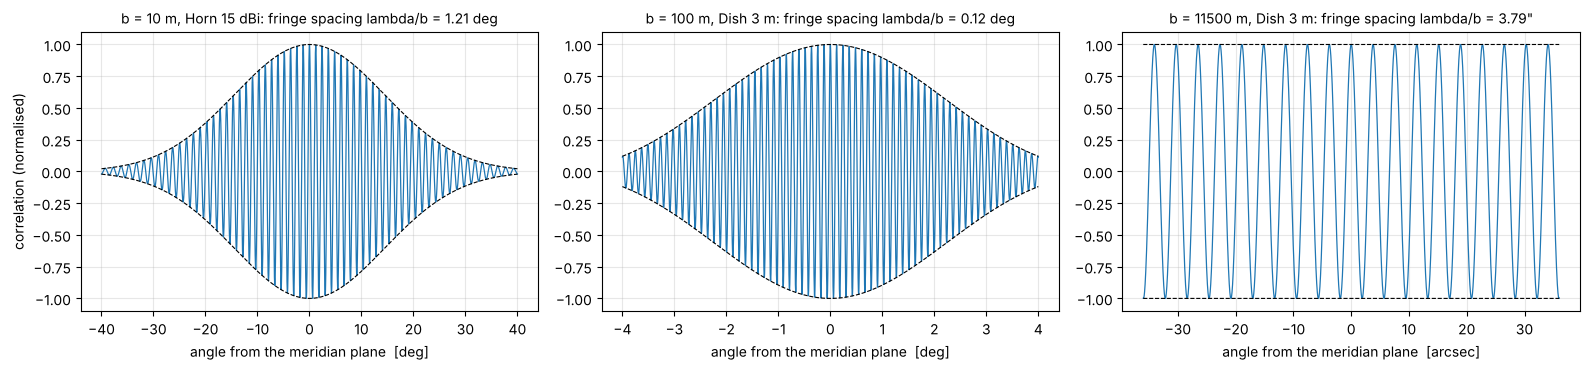

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, (b_m, ant, span) in zip(axes, ((10.0, horn, 40.0), (100.0, dish, 4.0), (11_500.0, dish, 0.01))):
    th = np.linspace(-span, span, 4001)
    R = ant.beam(np.abs(th)) * np.cos(2 * np.pi * b_m * np.sin(np.radians(th)) / LAM)
    unit, f = ("deg", 1.0) if span >= 1 else ("arcsec", 3600.0)
    ax.plot(th * f, R, lw=0.9)
    ax.plot(th * f, ant.beam(np.abs(th)), "k--", lw=0.8)
    ax.plot(th * f, -ant.beam(np.abs(th)), "k--", lw=0.8)
    sp = np.degrees(LAM / b_m)
    lab = f"{sp:.2f} deg" if sp > 0.1 else f"{sp * 3600:.2f}\""
    ax.set_title(f"b = {b_m:g} m, {ant.name}: fringe spacing lambda/b = {lab}", fontsize=10)
    ax.set_xlabel(f"angle from the meridian plane  [{unit}]"); ax.grid(alpha=0.3)
axes[0].set_ylabel("correlation (normalised)")
fig.tight_layout(); plt.show()

## 2. Fringes move: the fringe rate

The Earth's rotation sweeps the source through the fringe pattern; the phase $2\pi b\sin\theta/\lambda$ changes with time. For an east–west baseline the **natural fringe rate** is

$$f_F = \omega_E\,\frac{b}{\lambda}\,\cos\delta\,\cos H ,\qquad \omega_E = 7.29\cdot10^{-5}\ \mathrm{rad/s},$$

largest at transit ($H = 0$), zero at $H = \pm 6$ h. Ten metres give a few millihertz – one fringe every few minutes, as in the Sun transit with two horns (notebook 04); 11.5 km give a few hertz.

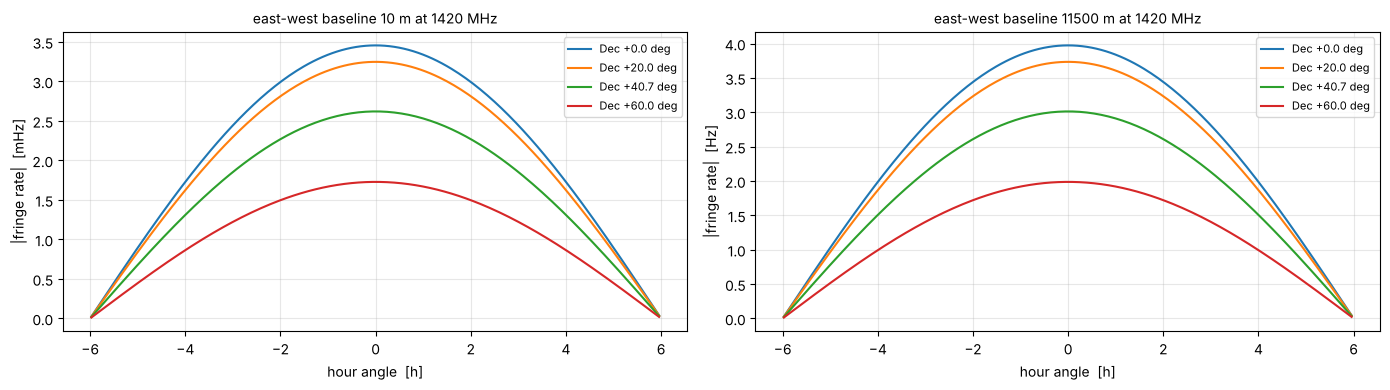

b =     10 m: f_F at transit (Dec 0) = 0.003455 Hz, period 289.4 s
b =    100 m: f_F at transit (Dec 0) = 0.03455 Hz, period 28.94 s
b =   1000 m: f_F at transit (Dec 0) = 0.3455 Hz, period 2.894 s
b =  11500 m: f_F at transit (Dec 0) = 3.973 Hz, period 0.2517 s


In [3]:
ha = np.linspace(-6, 6, 241)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, b_m, unit, f in ((axes[0], 10.0, "mHz", 1e3), (axes[1], 11_500.0, "Hz", 1.0)):
    for dec in (0.0, 20.0, 40.7, 60.0):
        o = Observation(baseline(b_m), ra_deg=0.0, dec_deg=dec, ha_range_h=(-6, 6), t_int_s=180,
                        min_elev_deg=-90, date=DATE)
        ax.plot(o.hour_angles() / 15, np.abs(o.fringe_rate_hz()[0]) * f, label=f"Dec {dec:+.1f} deg")
    ax.set_title(f"east-west baseline {b_m:g} m at 1420 MHz", fontsize=10)
    ax.set_xlabel("hour angle  [h]"); ax.set_ylabel(f"|fringe rate|  [{unit}]"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()
for b_m in (10, 100, 1000, 11_500):
    fF = OMEGA_SIDEREAL * b_m / LAM
    print(f"b = {b_m:6d} m: f_F at transit (Dec 0) = {fF:.4g} Hz, period {1 / fF:.4g} s")

## 3. The size of the source: fringe contrast

A source of finite size is a sum of points, each with its own fringe phase. When the source is comparable to the fringe spacing the fringes of its parts cancel partly: the **fringe contrast** – the visibility amplitude – drops. The Sun (34′) with two fixed horns: at 10 m (fringe spacing 1.2°) the contrast is still 74 %, at 26 m the first null of the disc visibility is reached, beyond it the contrast comes back weakly with inverted phase.

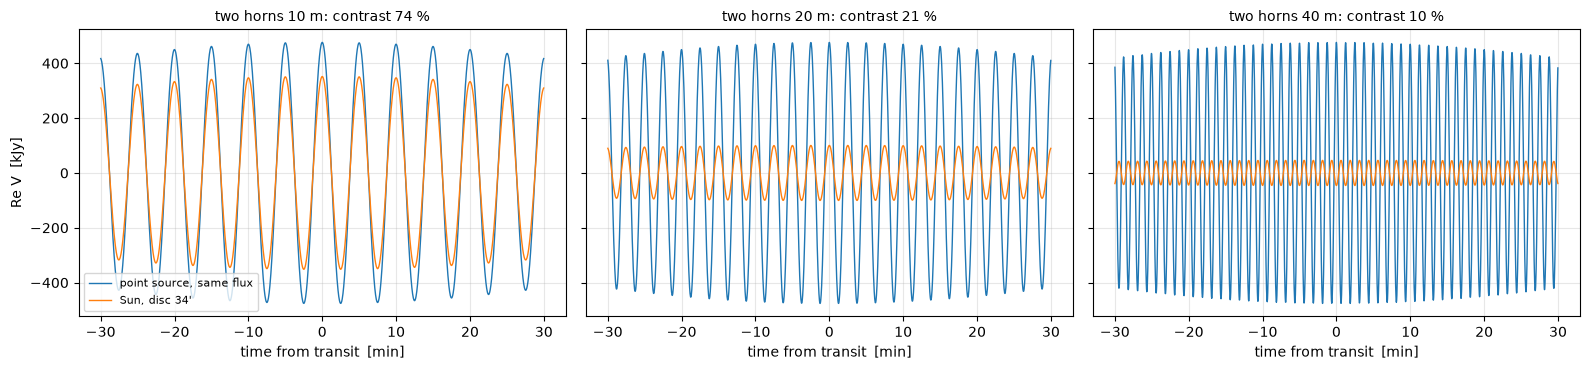

In [2]:
ra, dec = (float(x) for x in sun_radec_deg(mjd_from_iso(DATE + "T11:00:00")))
sun = SkyModel.from_json(CFG / "skies" / "sun_21cm.json"); sun.center = FieldCenter("Sun", ra, dec)
point = SkyModel([PointSource("point", 0, 0, sun.total_flux_jy)], center=sun.center, name="point source, same flux")
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
for ax, b_m in zip(axes, (10.0, 20.0, 40.0)):
    arr = baseline(b_m, antenna=horn)
    for s, style in ((point, "-"), (sun, "-")):
        v = TransitSimulator(arr, dec_deg=dec, ha_range_h=(-0.5, 0.5), t_dump_s=2.0, add_noise=False, date=DATE).run(s)
        ax.plot(v.ha_deg / 15 * 60, v.vis[:, 0].real / 1e3, style, lw=1, label=s.name if s is point else "Sun, disc 34'")
    contrast = abs(sun.visibility(b_m / LAM, 0)) / sun.total_flux_jy
    ax.set_title(f"two horns {b_m:g} m: contrast {contrast * 100:.0f} %", fontsize=10)
    ax.set_xlabel("time from transit  [min]"); ax.grid(alpha=0.3)
axes[0].set_ylabel("Re V  [kJy]"); axes[0].legend(fontsize=8)
fig.tight_layout(); plt.show()

## 4. Fringes in a long track: Cygnus A on 11.5 km, with zooms

The top panel shows the fringe-stopped visibility of Cygnus A on the project baseline over ±6 h (as in notebook 04). Below, four zooms of 5, 10, 15 and 20 minutes around the chosen hour angle (points: 10 s integrations with noise, line: model). Two kinds of fringe are at work:

* the **natural fringe** of the baseline, $f_F$ (a few hertz on 11.5 km) – removed by fringe stopping, it would run through the window hundreds to thousands of times;
* the **structure fringe** of the two hotspots, about 2′ apart: their visibilities beat with the rate $f_S = |\mathrm{d}(u\,\Delta l + v\,\Delta m)/\mathrm{d}t|$ ($\Delta l, \Delta m$: separation of the hotspots in radians). This is the oscillation of $|V|$ seen in the track – a few minutes per period, faster where the baseline cuts the jet axis more steeply.

Each zoom gives both values and the number of periods in the window.

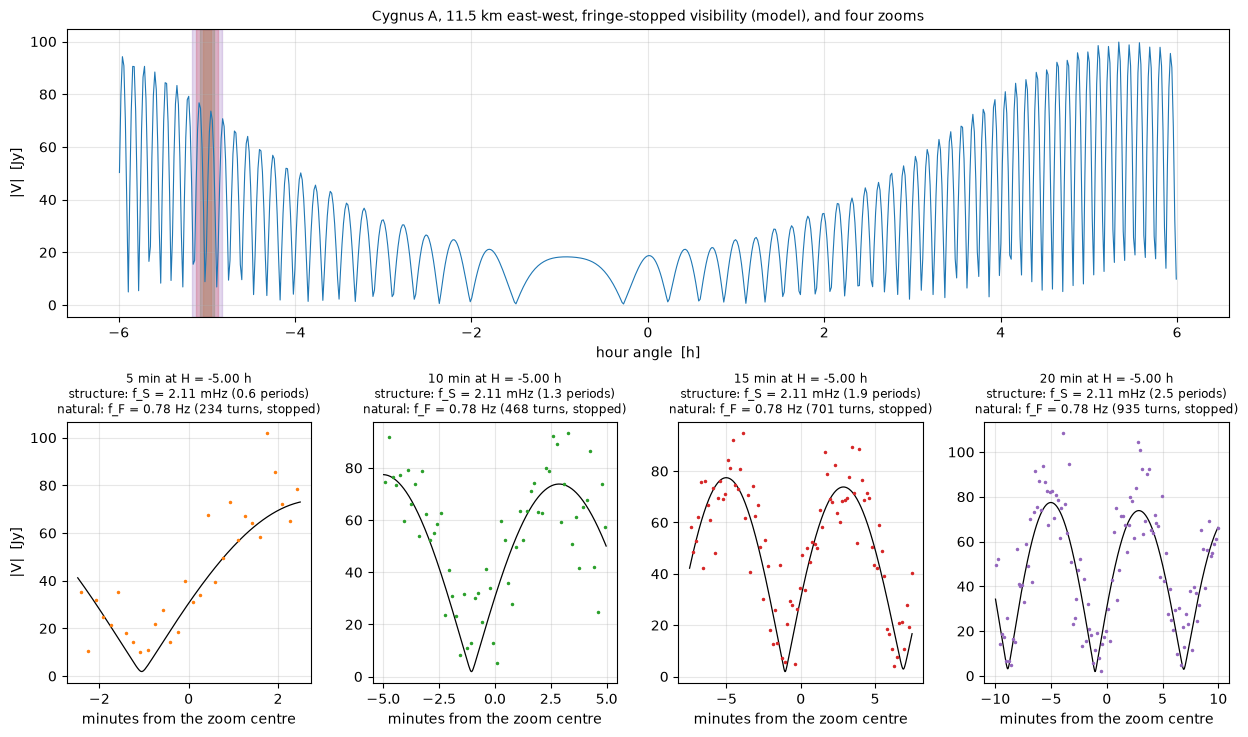

H = -5.00 h: structure fringe period 7.9 min, natural fringe period 1283 ms


In [3]:
cyga = SkyModel.from_json(CFG / "skies" / "cyg_a.json")
target = baseline(11_500.0)
hs = [c for c in cyga if "hotspot" in c.name]
dlm = np.radians([hs[0].dx_deg - hs[1].dx_deg, hs[0].dy_deg - hs[1].dy_deg])   # hotspot separation [rad]

def track(ha0_h, half_h, t_int_s, noise=True, seed=3):
    o = Observation.from_sky(cyga, target, ha_range_h=(ha0_h - half_h, ha0_h + half_h), t_int_s=t_int_s,
                             min_elev_deg=-90, date=DATE)
    return o, VisibilitySimulator(add_noise=noise, seed=seed).run(cyga, o)

def fringe_values(ha_h):
    o = Observation.from_sky(cyga, target, ha_range_h=(ha_h - 0.01, ha_h + 0.01), t_int_s=6, min_elev_deg=-90, date=DATE)
    q = o.uvw()[0]
    t = o.hour_angles() / 15 * 3600 * 0.99727              # seconds
    ph = q[:, 0] * dlm[0] + q[:, 1] * dlm[1]
    f_s = abs(np.polyfit(t, ph, 1)[0])
    f_f = abs(float(np.mean(o.fringe_rate_hz()[0])))
    return f_f, f_s

def fringe_figure(ha0_h=-5.0):
    o_all, v_all = track(0.0, 6.0, 60, noise=False)
    fig = plt.figure(figsize=(15, 8.5))
    gs = fig.add_gridspec(2, 4, height_ratios=[1.1, 1.0], hspace=0.38, wspace=0.25)
    ax0 = fig.add_subplot(gs[0, :])
    ax0.plot(v_all.ha_deg / 15, np.abs(v_all.vis[:, 0]), lw=0.8, color="C0")
    ax0.set_xlabel("hour angle  [h]"); ax0.set_ylabel("|V|  [Jy]"); ax0.grid(alpha=0.3)
    ax0.set_title("Cygnus A, 11.5 km east-west, fringe-stopped visibility (model), and four zooms", fontsize=10)
    f_f, f_s = fringe_values(ha0_h)
    for k, w_min in enumerate((5, 10, 15, 20)):
        half = w_min / 2 / 60
        ax0.axvspan(ha0_h - half, ha0_h + half, color=f"C{k + 1}", alpha=0.25)
        _, vz = track(ha0_h, half, 10.0, noise=True, seed=10 + k)
        _, vm = track(ha0_h, half, 2.0, noise=False)
        ax = fig.add_subplot(gs[1, k])
        tm = (vz.ha_deg / 15 - ha0_h) * 60
        ax.plot((vm.ha_deg / 15 - ha0_h) * 60, np.abs(vm.vis[:, 0]), color="k", lw=0.9)
        ax.plot(tm, np.abs(vz.vis[:, 0]), ".", ms=3, color=f"C{k + 1}")
        ax.set_xlabel("minutes from the zoom centre"); ax.grid(alpha=0.3)
        if k == 0:
            ax.set_ylabel("|V|  [Jy]")
        w_s = w_min * 60
        ax.set_title(f"{w_min} min at H = {ha0_h:+.2f} h\n"
                     f"structure: f_S = {f_s * 1e3:.2f} mHz ({w_s * f_s:.1f} periods)\n"
                     f"natural: f_F = {f_f:.2f} Hz ({w_s * f_f:,.0f} turns, stopped)", fontsize=8.5)
    plt.show()
    print(f"H = {ha0_h:+.2f} h: structure fringe period {1 / f_s / 60:.1f} min, natural fringe period {1 / f_f * 1e3:.0f} ms")

fringe_figure(-5.0)

Near transit the structure fringe slows down (the projected baseline changes direction slowly there and the hotspot pair lies almost along the fringes), the natural fringe is fastest. Away from transit it is the other way round:

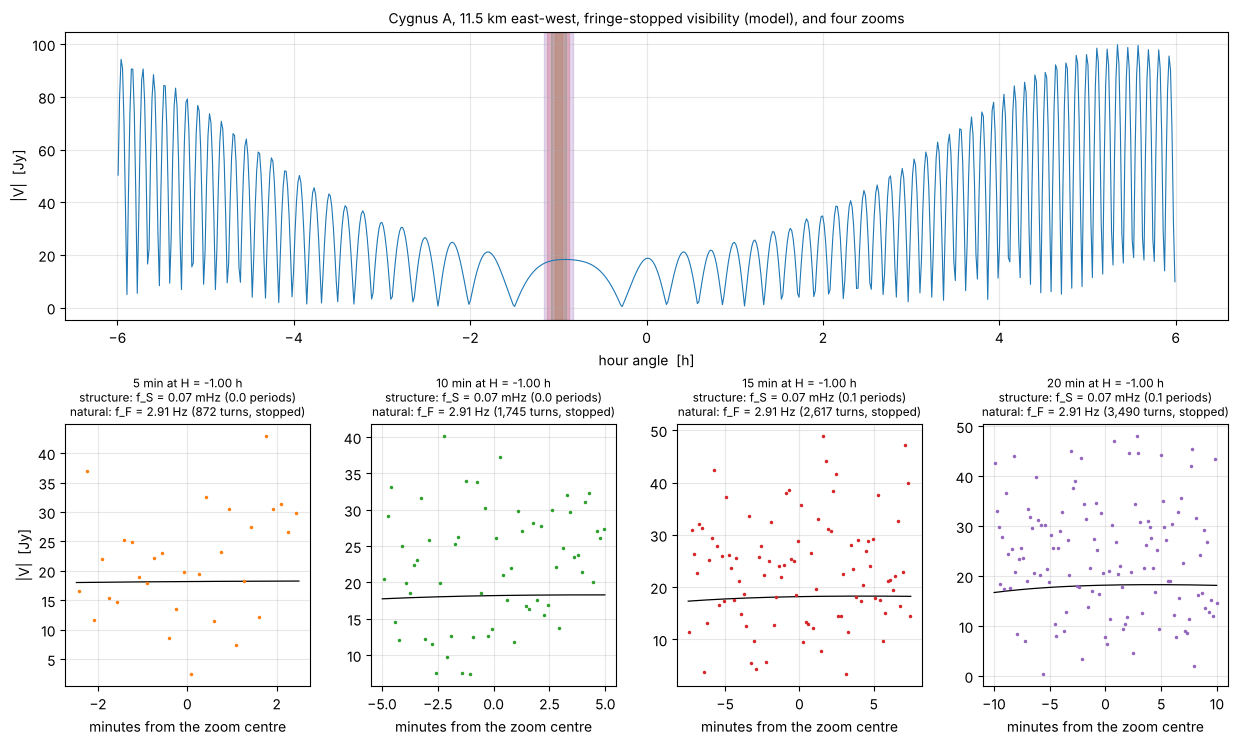

H = -1.00 h: structure fringe period 242.8 min, natural fringe period 344 ms


In [6]:
fringe_figure(-1.0)

## 5. Selector

Move the zoom centre through the track and watch both fringe rates change. (Needs a running kernel.)

In [4]:
import ipywidgets as widgets
from IPython.display import display
display(widgets.interactive(fringe_figure, {"manual": True},
        ha0_h=widgets.FloatSlider(value=-5.0, min=-5.8, max=5.8, step=0.1, description="centre H [h]",
                                  layout=widgets.Layout(width="60%"))))

interactive(children=(FloatSlider(value=-5.0, description='centre H [h]', layout=Layout(width='60%'), max=5.8,…